# 04. Gradient boosting from scratch

Bagging averages *independent* deep trees to cut variance. Boosting adds *small* trees **in sequence**,
each one correcting what the ensemble so far gets wrong, to cut bias.

For binary log loss with score $F(x)$ (log-odds) and $p = \sigma(F)$:
$$\ell(y, F) = -[y\log p + (1-y)\log(1-p)], \qquad -\frac{\partial \ell}{\partial F} = y - p.$$

**Gradient boosting** (Friedman 2001):
1. Start from $F_0 = \log\frac{\bar y}{1-\bar y}$.
2. For $m = 1..M$: compute residuals $r_i = y_i - p_i$; fit a regression tree to $r$; set each leaf's
   value by one Newton step, $\gamma = \frac{\sum r_i}{\sum p_i(1-p_i)}$; update $F \leftarrow F + \eta\,\gamma$.

The learning rate $\eta$ (shrinkage) makes each step small, so many trees share the work.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
from river_health import modeling as M
t = M.prepare(pd.read_parquet(ROOT / "data" / "processed" / "river_features.parquet"))
# a small, readable working set used throughout
F = ["up_stw_dwf_m3d_per_km2", "up_spill_hours_per_km2", "up_lc_urban", "up_lc_arable",
     "up_lc_improved_grass", "up_lc_seminatural", "up_area_km2", "local_n_private_sewage"]
d = t[t.phos_good.notna()].reset_index(drop=True)
X, y = d[F].to_numpy(float), d.phos_good.to_numpy(int)
groups = d.management_catchment.to_numpy()
print(X.shape, "share with good phosphate:", y.mean().round(3))

(3706, 8) share with good phosphate: 0.484


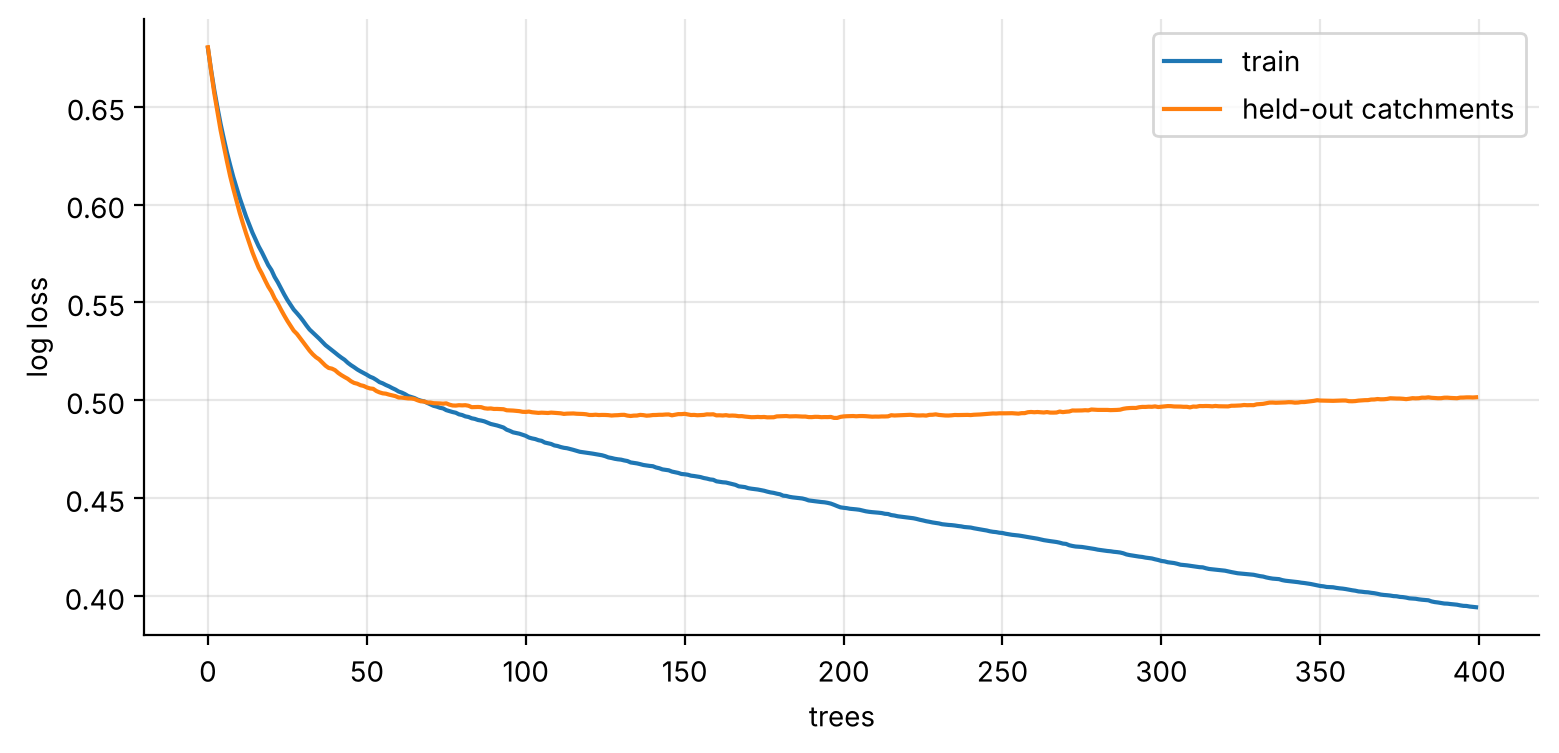

best number of trees on held-out fold: 199


In [2]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score, log_loss
sig = lambda z: 1 / (1 + np.exp(-z))

class Boost:
    def __init__(self, M=300, eta=0.05, depth=3, min_leaf=30):
        self.M, self.eta, self.depth, self.min_leaf = M, eta, depth, min_leaf
    def fit(self, X, y):
        self.F0 = np.log(y.mean() / (1 - y.mean())); F = np.full(len(y), self.F0); self.trees = []
        for m in range(self.M):
            p = sig(F); r = y - p
            tr = DecisionTreeRegressor(max_depth=self.depth, min_samples_leaf=self.min_leaf).fit(X, r)
            leaf = tr.apply(X); vals = {}
            for l in np.unique(leaf):                      # Newton step per leaf
                k = leaf == l
                vals[l] = r[k].sum() / max((p[k] * (1 - p[k])).sum(), 1e-9)
            self.trees.append((tr, vals))
            F += self.eta * np.vectorize(vals.get)(leaf)
        return self
    def staged(self, X):
        F = np.full(len(X), self.F0)
        for tr, vals in self.trees:
            F = F + self.eta * np.vectorize(vals.get)(tr.apply(X)); yield sig(F)

folds = list(StratifiedGroupKFold(5, shuffle=True, random_state=0).split(X, y, groups))
a, b = folds[0]
bst = Boost(M=400, eta=0.05).fit(X[a], y[a])
tr_ll = [log_loss(y[a], p) for p in bst.staged(X[a])]
te_ll = [log_loss(y[b], p) for p in bst.staged(X[b])]
plt.plot(tr_ll, label="train"); plt.plot(te_ll, label="held-out catchments")
plt.xlabel("trees"); plt.ylabel("log loss"); plt.legend(); plt.show()
print("best number of trees on held-out fold:", int(np.argmin(te_ll)) + 1)

Unlike a forest, boosting **can overfit by adding trees** (here the held-out minimum is near 200 trees): training loss keeps falling, held-out loss
bottoms out and turns up. The number of trees is a tuning parameter, usually set by **early stopping**.

## Learning rate vs number of trees

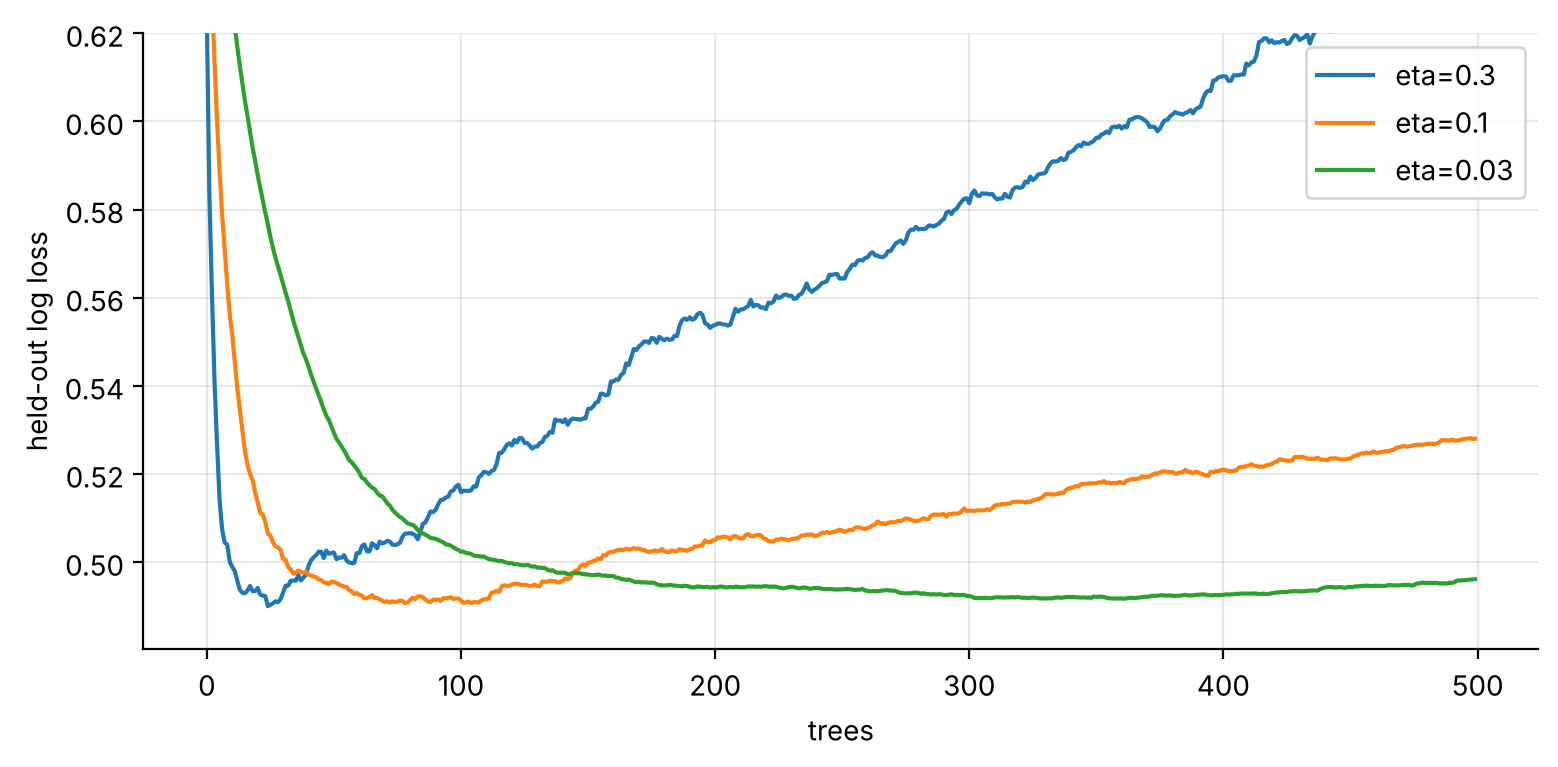

In [3]:
for eta in [0.3, 0.1, 0.03]:
    bb = Boost(M=500, eta=eta).fit(X[a], y[a])
    plt.plot([log_loss(y[b], p) for p in bb.staged(X[b])], label=f"eta={eta}")
plt.xlabel("trees"); plt.ylabel("held-out log loss"); plt.ylim(None, 0.62); plt.legend(); plt.show()

Smaller steps need more trees but reach a lower, flatter minimum: shrinkage is regularisation.

## Does it match a library?

In [4]:
from sklearn.ensemble import GradientBoostingClassifier
oof_ours, oof_sk = np.zeros(len(y)), np.zeros(len(y))
for a_, b_ in folds:
    oof_ours[b_] = list(Boost(M=200, eta=0.05).fit(X[a_], y[a_]).staged(X[b_]))[-1]
    oof_sk[b_] = GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3,
                                            min_samples_leaf=30, random_state=0).fit(X[a_], y[a_]).predict_proba(X[b_])[:, 1]
print(f"spatial-CV AUC  ours {roc_auc_score(y, oof_ours):.3f}   sklearn {roc_auc_score(y, oof_sk):.3f}")
print("correlation of predictions:", np.corrcoef(oof_ours, oof_sk)[0, 1].round(4))

spatial-CV AUC  ours 0.806   sklearn 0.806
correlation of predictions: 1.0
